<a href="https://colab.research.google.com/github/royam0820/Jev-Meetup/blob/main/jev_tabular_hybrid_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/royam0820/Jev-Meetup/blob/main/tabular_jev_hybrid/jev_tabular_hybrid.ipynb)

**Run on the real `bluebook-for-bulldozers` data (fastai ch.9):**

1. Accept the competition rules on Kaggle (same account as your token).
2. Kaggle → *Settings → API → Generate New Token* (a `KGAT_...` token).
3. In Colab 🔑 Secrets add `KAGGLE_API_KEY` (the token) and `OPENROUTER_API_KEY`, with notebook access on.

No Kaggle credentials? Drop `bluebook-for-bulldozers.zip` next to the notebook (or in `/content`).
With neither, the notebook falls back to the small UCI automobile dataset so the pipeline still runs end to end.

# Jev TypeSafe × Gradient-Boosted Regressor: Hybrid Tabular Price Prediction

This notebook demonstrates a **hybrid pattern**: the Jev decision model extracts semantic features
from text/categorical columns, and those features are fed into tree-based regressors.

**Fair comparison.** Jev is called once per row, so the head-to-head runs on an *experiment subset*
(`EXP_N_TRAIN` + `EXP_N_VALID` rows). Baseline and hybrid models are trained on exactly the same rows.
In bulldozer mode, a full-data baseline (~400k rows) is also reported as the reference ceiling.

## 1. Setup & Configuration

In [1]:
import os, json, time, warnings, math, sys
import numpy as np
import pandas as pd
from concurrent.futures import ThreadPoolExecutor, as_completed
import requests
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

try:
    import xgboost as xgb
    HAS_XGB = True
    print("✓ xgboost available")
except ImportError:
    HAS_XGB = False
    print("✗ xgboost not available, skipping XGBoost models")

warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def colab_secret(name):
    """Read a Colab secret; None outside Colab or if missing/not shared with the notebook."""
    if not IN_COLAB:
        return None
    try:
        from google.colab import userdata
        v = userdata.get(name)
        return v.strip() if isinstance(v, str) and v.strip() else None
    except Exception:
        return None

# Jev config
JEV_URL = "https://openrouter.ai/api/alpha/decisions"
JEV_MODEL = "typesafe/jev-1.14"
JEV_THREADS = 8
JEV_RETRIES = 3

# Experiment subset (rows sent to Jev = EXP_N_TRAIN + EXP_N_VALID)
EXP_N_TRAIN = 1200
EXP_N_VALID = 300
SEED = 42

API_KEY = os.environ.get("OPENROUTER_API_KEY") or colab_secret("OPENROUTER_API_KEY")
assert API_KEY, "OPENROUTER_API_KEY not set. Add it to your environment or Colab Secrets."

# Portable dirs (override with env vars)
OUT_DIR  = os.environ.get("JEV_OUT_DIR", "./jev_tabular_out")
DATA_DIR = os.environ.get("BULLDOZER_DIR", "/tmp/bulldozer" if IN_COLAB else "./data/bulldozer")
os.makedirs(OUT_DIR, exist_ok=True)

print(f"Colab={IN_COLAB} | model={JEV_MODEL} | experiment={EXP_N_TRAIN}+{EXP_N_VALID} rows | threads={JEV_THREADS}")

✓ xgboost available
Colab=True | model=typesafe/jev-1.14 | experiment=1200+300 rows | threads=8


## 2. Load & Clean Data

### 2a. Kaggle authentication
Prefers a new-style `KGAT_` token (written to `~/.kaggle/access_token` + `KAGGLE_API_TOKEN`).
A stale `kaggle.json` is removed in that case, because it caused the 401 errors.

In [2]:
import pathlib, subprocess, shutil

KDIR = pathlib.Path.home() / ".kaggle"
KJSON, KTOKEN = KDIR / "kaggle.json", KDIR / "access_token"
COMPETITION = "bluebook-for-bulldozers"

def setup_kaggle_auth():
    tok = (os.environ.get("KAGGLE_API_TOKEN") or colab_secret("KAGGLE_API_KEY")
           or colab_secret("KAGGLE_API_TOKEN") or colab_secret("KAGGLE_KEY"))
    uname = os.environ.get("KAGGLE_USERNAME") or colab_secret("KAGGLE_USERNAME")
    KDIR.mkdir(parents=True, exist_ok=True)

    if tok and tok.startswith("KGAT"):                 # new-style token: bearer auth
        KJSON.unlink(missing_ok=True)                  # stale legacy creds -> 401
        KTOKEN.write_text(tok); KTOKEN.chmod(0o600)
        os.environ["KAGGLE_API_TOKEN"] = tok
        return "KGAT token -> access_token"
    if tok and tok.startswith("{"):                    # whole kaggle.json pasted as a secret
        KJSON.write_text(tok); KJSON.chmod(0o600)
        return "kaggle.json from secret"
    if tok and uname:                                  # legacy 32-hex key + username
        KJSON.write_text(json.dumps({"username": uname, "key": tok})); KJSON.chmod(0o600)
        return "legacy key + username -> kaggle.json"
    if tok:
        print("! Secret is neither a KGAT_ token nor paired with KAGGLE_USERNAME - ignoring it.")
    if KTOKEN.exists():
        os.environ.setdefault("KAGGLE_API_TOKEN", KTOKEN.read_text().strip())
        return "existing ~/.kaggle/access_token"
    if KJSON.exists():
        return "existing ~/.kaggle/kaggle.json"
    return None

KAGGLE_OK = False
auth_source = setup_kaggle_auth()
print("Kaggle auth:", auth_source or "none (will use a local zip or the UCI fallback)")

if auth_source:
    if shutil.which("kaggle") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"], check=False)
    r = subprocess.run(["kaggle", "competitions", "files", "-c", COMPETITION],
                       capture_output=True, text=True)
    KAGGLE_OK = r.returncode == 0
    if KAGGLE_OK:
        print("✓ Kaggle API access to", COMPETITION, "confirmed")
    else:
        msg = (r.stderr or r.stdout or "").strip()[-400:]
        print("✗ Kaggle check failed:", msg)
        if "401" in msg:
            print("  -> token rejected: regenerate it in Kaggle Settings > API and update the secret.")
        elif "403" in msg:
            print("  -> rules not accepted by THIS account (or phone verification missing).")

Kaggle auth: KGAT token -> access_token
✓ Kaggle API access to bluebook-for-bulldozers confirmed


### 2b. Load bulldozers (local zip → Kaggle API → UCI fallback)

In [3]:
import glob, zipfile, urllib.request

def extract_all_zips(folder):
    """Extract every zip in folder, including nested ones (Train.zip, Valid.zip, ...)."""
    done = set()
    while True:
        todo = [z for z in glob.glob(os.path.join(folder, "*.zip")) if z not in done]
        if not todo:
            return
        for z in todo:
            try:
                with zipfile.ZipFile(z) as zf:
                    zf.extractall(folder)
            except zipfile.BadZipFile:
                print("  skipping bad zip:", z)
            done.add(z)

def load_bulldozer(folder):
    """Return a labelled DataFrame, or None if no usable CSV is present."""
    p = lambda f: os.path.join(folder, f)
    read = lambda f: pd.read_csv(p(f), low_memory=False, parse_dates=["saledate"])
    if os.path.exists(p("TrainAndValid.csv")):
        return read("TrainAndValid.csv")
    if os.path.exists(p("Train.csv")):
        parts = [read("Train.csv")]
        # Valid.csv has no SalePrice: only usable with ValidSolution.csv
        if os.path.exists(p("Valid.csv")) and os.path.exists(p("ValidSolution.csv")):
            va = read("Valid.csv")
            sol = pd.read_csv(p("ValidSolution.csv"))[["SalesID", "SalePrice"]]
            parts.append(va.drop(columns=["SalePrice"], errors="ignore").merge(sol, on="SalesID"))
        return pd.concat(parts, ignore_index=True)
    return None

os.makedirs(DATA_DIR, exist_ok=True)
MODE, df_raw = None, None

# (A) Data already extracted from a previous run
df_raw = load_bulldozer(DATA_DIR)

# (B) Manually uploaded zip
if df_raw is None:
    manual = [z for pat in ("/content/*ulldozer*.zip", "./*ulldozer*.zip") for z in glob.glob(pat)]
    if manual:
        print("Using manually uploaded zip:", manual[0])
        shutil.copy(manual[0], DATA_DIR)
        extract_all_zips(DATA_DIR)
        df_raw = load_bulldozer(DATA_DIR)

# (C) Kaggle API download
if df_raw is None and KAGGLE_OK:
    print("Downloading from Kaggle...")
    r = subprocess.run(["kaggle", "competitions", "download", "-c", COMPETITION, "-p", DATA_DIR],
                       capture_output=True, text=True)
    if r.returncode != 0:
        print("kaggle download failed:", (r.stderr or r.stdout or "")[-600:])
    extract_all_zips(DATA_DIR)
    df_raw = load_bulldozer(DATA_DIR)
    if df_raw is None:
        print("! No usable CSV after download. Files:", sorted(os.listdir(DATA_DIR)))

if df_raw is not None:
    MODE = "bulldozer"
else:
    # (D) UCI automobile fallback
    FALLBACK_CANDIDATES = [
        os.path.join(OUT_DIR, "data", "imports-85.data"),
        "./data/imports-85.data",
        "./tabular_jev_hybrid/data/imports-85.data",
    ]
    FALLBACK_PATH = next((f for f in FALLBACK_CANDIDATES if os.path.exists(f)), FALLBACK_CANDIDATES[0])
    if not os.path.exists(FALLBACK_PATH):
        os.makedirs(os.path.dirname(FALLBACK_PATH), exist_ok=True)
        print(f"Downloading UCI fallback to {FALLBACK_PATH}...")
        urllib.request.urlretrieve(
            "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data",
            FALLBACK_PATH)
    UCI_COLS = [
        "symboling","normalized_losses","make","fuel_type","aspiration","num_of_doors",
        "body_style","drive_wheels","engine_location","wheel_base","length","width",
        "height","curb_weight","engine_type","num_of_cylinders","engine_size","fuel_system",
        "bore","stroke","compression_ratio","horsepower","peak_rpm","city_mpg","highway_mpg","price"
    ]
    df_raw = pd.read_csv(FALLBACK_PATH, names=UCI_COLS, na_values="?")
    MODE = "fallback_automobile"

print(f"▶ MODE = {MODE}  |  shape = {df_raw.shape}")

▶ MODE = bulldozer  |  shape = (412698, 53)


### 2c. Clean & split

In [4]:
def is_text(s):
    return not pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_datetime64_any_dtype(s)

if MODE == "bulldozer":
    TARGET = "SalePrice"
    df = df_raw.dropna(subset=[TARGET]).copy()
    df["saleYear"] = df["saledate"].dt.year
    df["saleMonth"] = df["saledate"].dt.month
    df["saleDayOfWeek"] = df["saledate"].dt.dayofweek
    df["saleDayOfYear"] = df["saledate"].dt.dayofyear
    df.loc[df["YearMade"] < 1900, "YearMade"] = 1950          # 1000 = "unknown" placeholder (fastai)
    df["MachineHoursCurrentMeter"] = df["MachineHoursCurrentMeter"].replace(0, np.nan)
    df = df.drop(columns=["saledate", "SalesID"], errors="ignore")
    # Time-based split, as in the competition: predict 2012 sales from earlier ones
    train_mask = df["saleYear"] < 2012
    df_train, df_valid = df[train_mask].copy(), df[~train_mask].copy()
else:
    TARGET = "price"
    df = df_raw.dropna(subset=[TARGET]).copy()
    df[TARGET] = df[TARGET].astype(float)
    df_train, df_valid = train_test_split(df, test_size=0.2, random_state=SEED)

TEXT_COLS = [c for c in df.columns if c != TARGET and is_text(df[c])]
print(f"Full data -> Train: {len(df_train):,}, Valid: {len(df_valid):,}")
print(f"Target: {TARGET} | {len(TEXT_COLS)} text cols: {TEXT_COLS[:12]}{' ...' if len(TEXT_COLS) > 12 else ''}")

# Experiment subset: identical rows for baseline, hybrid and Jev-only
exp_train = df_train.sample(min(EXP_N_TRAIN, len(df_train)), random_state=SEED)
exp_valid = df_valid.sample(min(EXP_N_VALID, len(df_valid)), random_state=SEED)
print(f"Experiment subset -> Train: {len(exp_train):,}, Valid: {len(exp_valid):,}")

Full data -> Train: 401,125, Valid: 11,573
Target: SalePrice | 44 text cols: ['UsageBand', 'fiModelDesc', 'fiBaseModel', 'fiSecondaryDesc', 'fiModelSeries', 'fiModelDescriptor', 'ProductSize', 'fiProductClassDesc', 'state', 'ProductGroup', 'ProductGroupDesc', 'Drive_System'] ...
Experiment subset -> Train: 1,200, Valid: 300


## 3. Baseline Models

In [5]:
def prepare_baseline_features(df_tr, df_va, target):
    """Ordinal-encode categoricals, median-fill numerics (fit on train only)."""
    feature_cols = [c for c in df_tr.columns if c != target]
    cat_cols = [c for c in feature_cols if is_text(df_tr[c])]
    num_cols = [c for c in feature_cols if c not in cat_cols]

    tr, va = df_tr[feature_cols].copy(), df_va[feature_cols].copy()
    for c in cat_cols:
        tr[c] = tr[c].astype(str)
        va[c] = va[c].astype(str)
    for c in num_cols:
        tr[c] = pd.to_numeric(tr[c], errors="coerce")
        va[c] = pd.to_numeric(va[c], errors="coerce")
        med = tr[c].median()
        tr[c] = tr[c].fillna(med)
        va[c] = va[c].fillna(med)

    if cat_cols:
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
        tr[cat_cols] = enc.fit_transform(tr[cat_cols])
        va[cat_cols] = enc.transform(va[cat_cols])

    const_cols = [c for c in tr.columns if tr[c].nunique() <= 1]   # useless, and annoy HGB
    tr, va = tr.drop(columns=const_cols), va.drop(columns=const_cols)
    return tr.values.astype(np.float32), va.values.astype(np.float32), list(tr.columns)

def rmsle_from_log(y_true_log, y_pred_log):
    """RMSLE = RMSE of log-space predictions."""
    return math.sqrt(mean_squared_error(y_true_log, y_pred_log))

def make_models(n_rows):
    """RF leaf size scaled to data size (25 leaves on 160 rows underfits badly)."""
    big = n_rows > 50_000
    models = {
        "RandomForest": RandomForestRegressor(
            n_estimators=40, min_samples_leaf=25 if big else 3,
            max_samples=200_000 if n_rows > 200_000 else None,
            max_features=0.5, n_jobs=-1, random_state=SEED),
        "HistGradientBoosting": HistGradientBoostingRegressor(
            max_iter=200, max_depth=6, learning_rate=0.1, random_state=SEED),
    }
    if HAS_XGB:
        models["XGBoost"] = xgb.XGBRegressor(
            n_estimators=200, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=SEED)
    return models

def fit_eval(X_tr, y_tr, X_va, y_va, label):
    scores = {}
    for name, m in make_models(len(X_tr)).items():
        t = time.time()
        m.fit(X_tr, y_tr)
        scores[name] = rmsle_from_log(y_va, m.predict(X_va))
        print(f"  {label:<10} {name:<22} RMSLE {scores[name]:.4f}  ({time.time()-t:.1f}s)")
    return scores

y_exp_train = np.log1p(exp_train[TARGET].values)
y_exp_valid = np.log1p(exp_valid[TARGET].values)

In [6]:
# Baseline on the experiment subset
X_train, X_valid, feature_names = prepare_baseline_features(exp_train, exp_valid, TARGET)
print(f"Baseline features: {X_train.shape[1]}")
baseline_scores = fit_eval(X_train, y_exp_train, X_valid, y_exp_valid, "baseline")

# Full-data reference (bulldozer only; the experiment subset already IS the full data otherwise)
full_scores = None
if MODE == "bulldozer":
    print("\nFull-data reference (~400k rows, a few minutes on Colab)...")
    Xf_tr, Xf_va, _ = prepare_baseline_features(df_train, df_valid, TARGET)
    full_scores = fit_eval(Xf_tr, np.log1p(df_train[TARGET].values),
                           Xf_va, np.log1p(df_valid[TARGET].values), "full-data")
    del Xf_tr, Xf_va

Baseline features: 54
  baseline   RandomForest           RMSLE 0.4219  (0.5s)
  baseline   HistGradientBoosting   RMSLE 0.3925  (1.0s)
  baseline   XGBoost                RMSLE 0.3919  (2.8s)

Full-data reference (~400k rows, a few minutes on Colab)...
  full-data  RandomForest           RMSLE 0.2604  (52.4s)
  full-data  HistGradientBoosting   RMSLE 0.2659  (34.2s)
  full-data  XGBoost                RMSLE 0.2572  (20.8s)


## 4. Jev Feature Extraction
The questions are domain-specific: car questions for the automobile fallback, equipment questions for bulldozers.
Results are cached in `OUT_DIR`, so re-running does not pay for the same rows twice.

In [7]:
SCHEMAS = {
    "fallback_automobile": {
        "context": ["make", "fuel_type", "aspiration", "num_of_doors", "body_style", "drive_wheels",
                    "engine_location", "engine_type", "num_of_cylinders", "fuel_system",
                    "curb_weight", "engine_size", "horsepower", "wheel_base", "length", "width"],
        "category": {
            "instructions": "What kind of vehicle is this?",
            "criteria": {
                "sedan": "A standard sedan/saloon car", "coupe": "A sporty two-door coupe",
                "suv": "An SUV or crossover", "wagon": "A station wagon or estate",
                "hatchback": "A compact hatchback", "convertible": "A convertible/cabriolet",
                "truck": "A pickup truck or commercial vehicle", "luxury": "A luxury/premium vehicle",
                "sports": "A dedicated sports car", "economy": "An economy/budget vehicle"}},
        "segment": {
            "instructions": "What market segment does this vehicle target?",
            "criteria": {"economy": "Budget/economy segment", "standard": "Standard/mainstream segment",
                         "premium": "Premium/upmarket segment", "luxury": "Luxury/high-end segment"}},
    },
    "bulldozer": {
        "context": ["fiProductClassDesc", "ProductGroupDesc", "fiBaseModel", "fiModelDesc",
                    "fiSecondaryDesc", "fiModelSeries", "fiModelDescriptor", "ProductSize",
                    "Enclosure", "Hydraulics", "Drive_System", "Track_Type", "Blade_Type",
                    "Stick_Length", "YearMade", "MachineHoursCurrentMeter", "UsageBand",
                    "state", "saleYear"],
        "category": {
            "instructions": "What type of heavy equipment is this?",
            "criteria": {
                "track_type_tractor": "A crawler dozer / track-type tractor",
                "wheel_loader": "A wheel loader",
                "track_excavator": "A hydraulic track excavator",
                "backhoe_loader": "A backhoe loader",
                "motor_grader": "A motor grader",
                "skid_steer_loader": "A skid steer or compact track loader",
                "other": "Any other kind of machine"}},
        "segment": {
            "instructions": "What duty class / market segment does this machine serve?",
            "criteria": {"light": "Light-duty, rental or landscaping use",
                         "general": "General construction, mainstream",
                         "heavy": "Heavy construction or quarry work",
                         "mining": "Mining-class or specialized, very large"}},
    },
}
SCHEMA = SCHEMAS[MODE]
SIZE_KEYS = ["compact", "medium", "large"]

def build_questions(schema):
    return {
        "category": {"type": "choice", **schema["category"]},
        "size_class": {
            "type": "choice",
            "instructions": "What size class does this item belong to?",
            "criteria": {"compact": "Small, compact size", "medium": "Mid-size", "large": "Full-size or large"}},
        "market_segment": {"type": "choice", **schema["segment"]},
        "value_tier": {
            "type": "score",
            "instructions": "Rate the expected value/price tier of this item from cheapest to most expensive.",
            "criteria": ["very_cheap", "cheap", "moderate", "expensive", "very_expensive"]},
        "is_high_value": {
            "type": "noul",
            "instructions": "Is this a high-value or specialized item that commands a premium price?",
            "criteria": {"true": "Yes, high-value/specialized", "false": "No, standard/commodity"}},
    }

QUESTIONS = build_questions(SCHEMA)
HEADERS = {"Authorization": f"Bearer {API_KEY}", "Content-Type": "application/json"}

def to_state(row):
    """Row -> string dict, dropping missing / placeholder values instead of sending 'nan'."""
    out = {}
    for k, v in row.items():
        if v is None or (isinstance(v, float) and math.isnan(v)):
            continue
        s = str(v).strip()
        if s and s.lower() not in ("nan", "none", "none or unspecified", "unspecified"):
            out[k] = s
    return out

def jev_call(row_dict, retries=JEV_RETRIES):
    """Call Jev for one row. Returns (answers | None, cost, error | None)."""
    body = {"model": JEV_MODEL, "state": to_state(row_dict), "questions": QUESTIONS}
    err = None
    for attempt in range(retries):
        try:
            resp = requests.post(JEV_URL, json=body, headers=HEADERS, timeout=30)
            if resp.status_code == 200:
                data = resp.json()
                return data.get("answers", {}), data.get("usage", {}).get("cost", 0.0), None
            err = f"HTTP {resp.status_code}: {resp.text[:200]}"
            if resp.status_code in (400, 401, 402, 403, 404):    # not retryable
                break
            time.sleep(2 ** attempt)                             # 429 / 5xx backoff
        except Exception as e:
            err = repr(e)
            time.sleep(1)
    return None, 0.0, err

In [8]:
# Run Jev on the experiment rows (with on-disk cache)
all_rows = pd.concat([exp_train, exp_valid])
assert all_rows.index.is_unique
context_cols = [c for c in SCHEMA["context"] if c in all_rows.columns]
print("Context sent to Jev:", context_cols)

CACHE_PATH = os.path.join(OUT_DIR, f"jev_cache_{MODE}_{JEV_MODEL.replace('/', '_')}.json")
try:
    with open(CACHE_PATH) as f:
        cache = {int(k): v for k, v in json.load(f).items()}
except (FileNotFoundError, json.JSONDecodeError):
    cache = {}

todo = [i for i in all_rows.index if i not in cache]
print(f"{len(all_rows) - len(todo)} rows cached, sending {len(todo)} to Jev ({JEV_THREADS} threads)...")

t0, total_cost, errors = time.time(), 0.0, []
rows_by_idx = all_rows.loc[todo, context_cols].to_dict(orient="index")

with ThreadPoolExecutor(max_workers=JEV_THREADS) as pool:
    futures = {pool.submit(jev_call, rows_by_idx[i]): i for i in todo}
    for n, fut in enumerate(as_completed(futures), 1):
        idx = futures[fut]
        answers, cost, err = fut.result()
        if answers:
            cache[idx] = answers
            total_cost += cost
        else:
            errors.append(err)
        if n % 100 == 0:
            print(f"  {n}/{len(todo)} done...")

elapsed = time.time() - t0
with open(CACHE_PATH, "w") as f:
    json.dump({str(k): v for k, v in cache.items()}, f)

jev_results = {i: cache[i] for i in all_rows.index if i in cache}
failures = len(all_rows) - len(jev_results)
n_calls = len(todo)
print(f"Jev complete: {len(jev_results)}/{len(all_rows)} ok, {failures} failures, "
      f"{elapsed:.1f}s, ${total_cost:.6f} this run")
if errors:
    print("First error:", errors[0])
assert len(jev_results) > 0, "Every Jev call failed - check OPENROUTER_API_KEY and the error above."

Context sent to Jev: ['fiProductClassDesc', 'ProductGroupDesc', 'fiBaseModel', 'fiModelDesc', 'fiSecondaryDesc', 'fiModelSeries', 'fiModelDescriptor', 'ProductSize', 'Enclosure', 'Hydraulics', 'Drive_System', 'Track_Type', 'Blade_Type', 'Stick_Length', 'YearMade', 'MachineHoursCurrentMeter', 'UsageBand', 'state', 'saleYear']
0 rows cached, sending 1500 to Jev (8 threads)...
  100/1500 done...
  200/1500 done...
  300/1500 done...
  400/1500 done...
  500/1500 done...
  600/1500 done...
  700/1500 done...
  800/1500 done...
  900/1500 done...
  1000/1500 done...
  1100/1500 done...
  1200/1500 done...
  1300/1500 done...
  1400/1500 done...
  1500/1500 done...
Jev complete: 1500/1500 ok, 0 failures, 56.5s, $0.053936 this run


## 5. Build Jev Features & Hybrid Model

In [9]:
CAT_KEYS = list(SCHEMA["category"]["criteria"])
SEG_KEYS = list(SCHEMA["segment"]["criteria"])

def extract_jev_features(answers):
    """Flatten Jev answers into numeric features. Missing call -> neutral defaults + jev_ok=0."""
    answers = answers or {}
    hv, vt = answers.get("is_high_value", {}), answers.get("value_tier", {})
    cat, sc, ms = (answers.get(k, {}) for k in ("category", "size_class", "market_segment"))
    feats = {
        "jev_ok": float(bool(answers)),
        "jev_high_value_prob": hv.get("noul", 0.5),
        "jev_value_tier_score": vt.get("score", 2.0),
        "jev_value_tier_conf": vt.get("confidence", 0.0),
        "jev_category_conf": cat.get("confidence", 0.0),
        "jev_size_conf": sc.get("confidence", 0.0),
        "jev_market_conf": ms.get("confidence", 0.0),
    }
    for k in CAT_KEYS:
        feats[f"jev_cat_{k}"] = cat.get("probabilities", {}).get(k, 0.0)
    for k in SIZE_KEYS:
        feats[f"jev_size_{k}"] = sc.get("probabilities", {}).get(k, 0.0)
    for k in SEG_KEYS:
        feats[f"jev_market_{k}"] = ms.get("probabilities", {}).get(k, 0.0)
    return feats

df_jev = pd.DataFrame({i: extract_jev_features(jev_results.get(i)) for i in all_rows.index}).T
df_jev = df_jev.astype(float)
jev_feature_names = list(df_jev.columns)
print(f"Jev features: {len(jev_feature_names)} columns")
print(df_jev.head())

Jev features: 21 columns
        jev_ok  jev_high_value_prob  jev_value_tier_score  \
347851     1.0                 0.37                  1.77   
361528     1.0                 0.50                  1.90   
296035     1.0                 0.84                  3.23   
165866     1.0                 0.22                  1.22   
303180     1.0                 0.80                  2.97   

        jev_value_tier_conf  jev_category_conf  jev_size_conf  \
347851                 0.57                1.0           0.27   
361528                 0.61                1.0           0.53   
296035                 0.48                1.0           1.00   
165866                 0.57                1.0           0.98   
303180                 0.52                1.0           1.00   

        jev_market_conf  jev_cat_track_type_tractor  jev_cat_wheel_loader  \
347851             0.95                         0.0                   0.0   
361528             0.76                         1.0            

In [10]:
# Combine baseline + Jev features (same row order as X_train / X_valid)
X_train_jev = np.hstack([X_train, df_jev.loc[exp_train.index].values.astype(np.float32)])
X_valid_jev = np.hstack([X_valid, df_jev.loc[exp_valid.index].values.astype(np.float32)])
hybrid_feature_names = feature_names + jev_feature_names
print(f"Hybrid feature matrix: train={X_train_jev.shape}, valid={X_valid_jev.shape}")

hybrid_scores = fit_eval(X_train_jev, y_exp_train, X_valid_jev, y_exp_valid, "hybrid")

Hybrid feature matrix: train=(1200, 75), valid=(300, 75)
  hybrid     RandomForest           RMSLE 0.3969  (0.8s)
  hybrid     HistGradientBoosting   RMSLE 0.3727  (2.0s)
  hybrid     XGBoost                RMSLE 0.3772  (2.7s)


## 6. Jev-Only Baseline (No Feature Training)

In [11]:
# Map Jev's value_tier and market_segment to median train prices, then average the two
train_jev = df_jev.loc[exp_train.index].copy()
train_jev["price"] = exp_train[TARGET].values
valid_jev = df_jev.loc[exp_valid.index].copy()

_, edges = pd.qcut(train_jev["jev_value_tier_score"], q=5, retbins=True, duplicates="drop")
inner = edges[1:-1]                                     # same bin edges for train and valid
train_jev["vt_bin"] = np.digitize(train_jev["jev_value_tier_score"], inner)
valid_jev["vt_bin"] = np.digitize(valid_jev["jev_value_tier_score"], inner)
tier_price = train_jev.groupby("vt_bin")["price"].median()

seg_cols = [f"jev_market_{k}" for k in SEG_KEYS]
train_jev["seg"] = train_jev[seg_cols].idxmax(axis=1)
valid_jev["seg"] = valid_jev[seg_cols].idxmax(axis=1)
seg_price = train_jev.groupby("seg")["price"].median()

global_median = train_jev["price"].median()
tp = valid_jev["vt_bin"].map(tier_price).fillna(global_median)
sp = valid_jev["seg"].map(seg_price).fillna(global_median)
jev_only_preds = ((tp + sp) / 2).values

jev_only_rmsle = rmsle_from_log(y_exp_valid, np.log1p(jev_only_preds))
median_rmsle = rmsle_from_log(y_exp_valid, np.full(len(y_exp_valid), np.log1p(global_median)))
print(f"Jev-only RMSLE:              {jev_only_rmsle:.4f}")
print(f"Predict-the-median RMSLE:    {median_rmsle:.4f}   (floor to beat)")

Jev-only RMSLE:              0.5495
Predict-the-median RMSLE:    0.7409   (floor to beat)


## 7. Results & Visualization

In [12]:
results = {
    "mode": MODE,
    "n_train_full": len(df_train), "n_valid_full": len(df_valid),
    "n_train_exp": len(exp_train), "n_valid_exp": len(exp_valid),
    "jev_model": JEV_MODEL,
    "jev_rows_ok": len(jev_results), "jev_failures": failures,
    "jev_calls_this_run": n_calls,
    "jev_cost_this_run_usd": round(total_cost, 8),
    "jev_latency_seconds": round(elapsed, 1),
    "models": {}, "deltas": {},
}
for name in baseline_scores:
    results["models"][f"{name}_baseline"] = round(baseline_scores[name], 4)
    results["models"][f"{name}_hybrid"] = round(hybrid_scores[name], 4)
    results["deltas"][name] = round(baseline_scores[name] - hybrid_scores[name], 4)  # >0 = Jev helped
results["models"]["jev_only"] = round(jev_only_rmsle, 4)
results["models"]["median_predictor"] = round(median_rmsle, 4)
if full_scores:
    results["full_data_baseline"] = {k: round(v, 4) for k, v in full_scores.items()}

print("=" * 66)
print(f"RESULTS ({MODE}, experiment subset {len(exp_train)}+{len(exp_valid)} rows)")
print("=" * 66)
print(f"{'Model':<24}{'Baseline':>10}{'+ Jev':>10}{'Δ (↑ good)':>14}")
for name in baseline_scores:
    print(f"{name:<24}{baseline_scores[name]:>10.4f}{hybrid_scores[name]:>10.4f}{results['deltas'][name]:>+14.4f}")
print(f"{'Jev-only':<24}{jev_only_rmsle:>10.4f}")
print(f"{'Median predictor':<24}{median_rmsle:>10.4f}")
if full_scores:
    print("-" * 66)
    for name, v in full_scores.items():
        print(f"{name + ' (full data)':<24}{v:>10.4f}")
print("-" * 66)
print(f"Jev: {n_calls} calls this run, ${total_cost:.6f}, {elapsed:.1f}s")

with open(os.path.join(OUT_DIR, "results.json"), "w") as f:
    json.dump(results, f, indent=2)
print("✓ results.json saved")

RESULTS (bulldozer, experiment subset 1200+300 rows)
Model                     Baseline     + Jev    Δ (↑ good)
RandomForest                0.4219    0.3969       +0.0250
HistGradientBoosting        0.3925    0.3727       +0.0198
XGBoost                     0.3919    0.3772       +0.0146
Jev-only                    0.5495
Median predictor            0.7409
------------------------------------------------------------------
RandomForest (full data)    0.2604
HistGradientBoosting (full data)    0.2659
XGBoost (full data)         0.2572
------------------------------------------------------------------
Jev: 1500 calls this run, $0.053936, 56.5s
✓ results.json saved


✓ chart.png saved


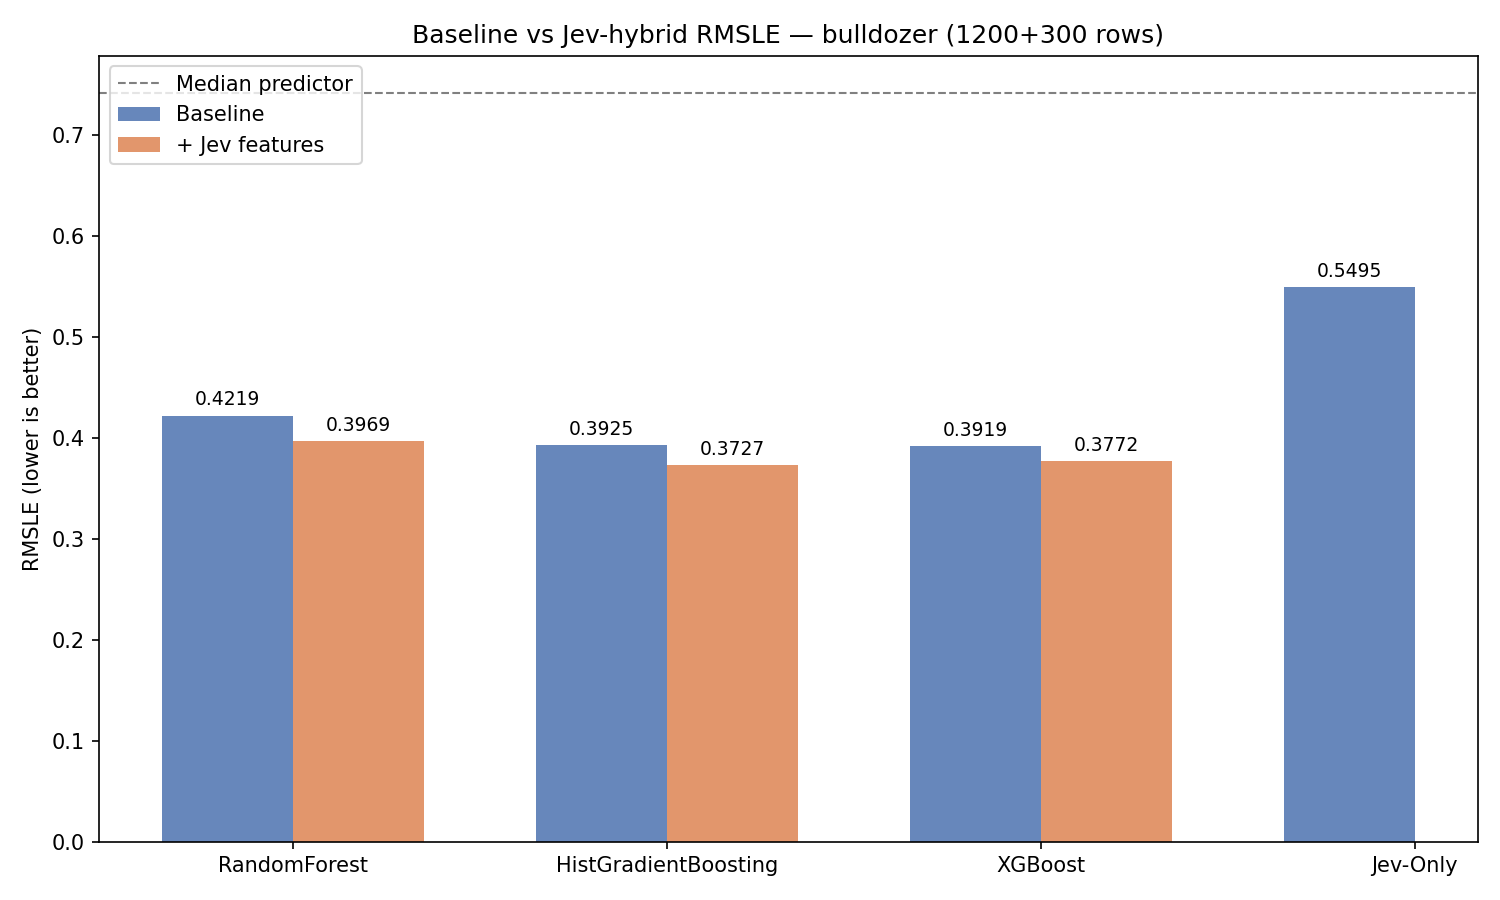

In [13]:
names = list(baseline_scores) + ["Jev-Only"]
base_vals = [baseline_scores[n] for n in baseline_scores] + [jev_only_rmsle]
hyb_vals = [hybrid_scores[n] for n in hybrid_scores] + [np.nan]

x, width = np.arange(len(names)), 0.35
fig, ax = plt.subplots(figsize=(10, 6))
b1 = ax.bar(x - width/2, base_vals, width, label="Baseline", color="#4C72B0", alpha=0.85)
b2 = ax.bar(x + width/2, hyb_vals, width, label="+ Jev features", color="#DD8452", alpha=0.85)
ax.axhline(median_rmsle, ls="--", lw=1, color="grey", label="Median predictor")
ax.set_ylabel("RMSLE (lower is better)")
ax.set_title(f"Baseline vs Jev-hybrid RMSLE — {MODE} ({len(exp_train)}+{len(exp_valid)} rows)")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.legend()
for bar in list(b1) + list(b2):
    h = bar.get_height()
    if np.isfinite(h):
        ax.annotate(f"{h:.4f}", (bar.get_x() + bar.get_width()/2, h), xytext=(0, 3),
                    textcoords="offset points", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
chart_path = os.path.join(OUT_DIR, "chart.png")
plt.savefig(chart_path, dpi=150)
plt.close(fig)
print("✓ chart.png saved")

from IPython.display import Image, display
display(Image(chart_path))

## 8. Conclusions

In [15]:
dataset = ("Kaggle Blue Book for Bulldozers (time split: valid = 2012 sales)"
           if MODE == "bulldozer" else "UCI Automobile (imports-85), random 80/20 split")
helped = [n for n, d in results["deltas"].items() if d > 0]
hurt = [n for n, d in results["deltas"].items() if d < 0]

rows = "\n".join(f"| {n} | {baseline_scores[n]:.4f} | {hybrid_scores[n]:.4f} | {results['deltas'][n]:+.4f} |"
                 for n in baseline_scores)
full_block = ""
if full_scores:
    full_block = "\n## Full-data reference (no Jev)\n" + "\n".join(
        f"- {n}: RMSLE {v:.4f} on {len(df_train):,} train rows" for n, v in full_scores.items()) + "\n"

caveats = [f"Experiment subset of {len(exp_train)} train / {len(exp_valid)} valid rows: "
           "differences of ~0.01 RMSLE are within noise; rerun with another SEED before concluding."]
if MODE != "bulldozer":
    caveats.append("Fallback dataset: add Kaggle credentials (see top cell) for the fastai ch.9 bulldozer run.")
caveats.append("Jev answers may change across model versions; the cache file is keyed by model name.")

summary = f"""# Jev Tabular Hybrid — Results Summary

## Mode: `{MODE}`
- Dataset: {dataset}
- Full data: {len(df_train):,} train / {len(df_valid):,} valid rows
- Experiment subset: {len(exp_train)} train / {len(exp_valid)} valid rows
- Metric: RMSLE (lower is better). Δ = baseline − hybrid (positive = Jev helped)

## Comparison (experiment subset)

| Model | Baseline RMSLE | Hybrid RMSLE | Δ |
|-------|---------------|-------------|---|
{rows}
| Jev-only (no feature training) | {jev_only_rmsle:.4f} | — | — |
| Median predictor | {median_rmsle:.4f} | — | — |
{full_block}
## Jev cost & latency
- {len(jev_results)}/{len(all_rows)} rows answered, {failures} failures
- This run: {n_calls} calls, ${total_cost:.6f}, {elapsed:.1f}s

## Reading the results
- Jev features helped: {", ".join(helped) or "none"}; hurt: {", ".join(hurt) or "none"}.
- Jev-only vs median predictor: {jev_only_rmsle:.4f} vs {median_rmsle:.4f} — how much price signal the
  zero-shot semantic answers carry on their own.
- Strong tree models with the raw columns usually already capture what Jev infers; Jev is best seen as a
  feature-enrichment layer, most useful when the raw text is messy or high-cardinality.

## Caveats
""" + "\n".join(f"- {c}" for c in caveats) + "\n"

with open(os.path.join(OUT_DIR, "results_summary.md"), "w") as f:
    f.write(summary)
print(summary)
print(f"✓ results_summary.md saved — all outputs in: {OUT_DIR}/")

# Jev Tabular Hybrid — Results Summary

## Mode: `bulldozer`
- Dataset: Kaggle Blue Book for Bulldozers (time split: valid = 2012 sales)
- Full data: 401,125 train / 11,573 valid rows
- Experiment subset: 1200 train / 300 valid rows
- Metric: RMSLE (lower is better). Δ = baseline − hybrid (positive = Jev helped)

## Comparison (experiment subset)

| Model | Baseline RMSLE | Hybrid RMSLE | Δ |
|-------|---------------|-------------|---|
| RandomForest | 0.4219 | 0.3969 | +0.0250 |
| HistGradientBoosting | 0.3925 | 0.3727 | +0.0198 |
| XGBoost | 0.3919 | 0.3772 | +0.0146 |
| Jev-only (no feature training) | 0.5495 | — | — |
| Median predictor | 0.7409 | — | — |

## Full-data reference (no Jev)
- RandomForest: RMSLE 0.2604 on 401,125 train rows
- HistGradientBoosting: RMSLE 0.2659 on 401,125 train rows
- XGBoost: RMSLE 0.2572 on 401,125 train rows

## Jev cost & latency
- 1500/1500 rows answered, 0 failures
- This run: 1500 calls, $0.053936, 56.5s

## Reading the results
- Jev features he